Dataset shape: (205, 26)
   car_ID  symboling                   CarName fueltype aspiration doornumber  \
0       1          3        alfa-romero giulia      gas        std        two   
1       2          3       alfa-romero stelvio      gas        std        two   
2       3          1  alfa-romero Quadrifoglio      gas        std        two   
3       4          2               audi 100 ls      gas        std       four   
4       5          2                audi 100ls      gas        std       four   

       carbody drivewheel enginelocation  wheelbase  ...  enginesize  \
0  convertible        rwd          front       88.6  ...         130   
1  convertible        rwd          front       88.6  ...         130   
2    hatchback        rwd          front       94.5  ...         152   
3        sedan        fwd          front       99.8  ...         109   
4        sedan        4wd          front       99.4  ...         136   

   fuelsystem  boreratio  stroke compressionratio horse

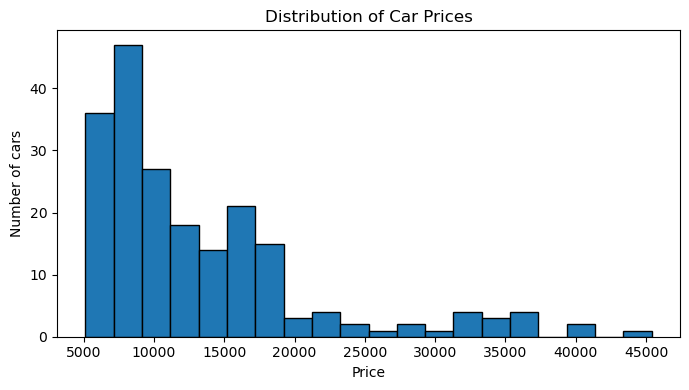

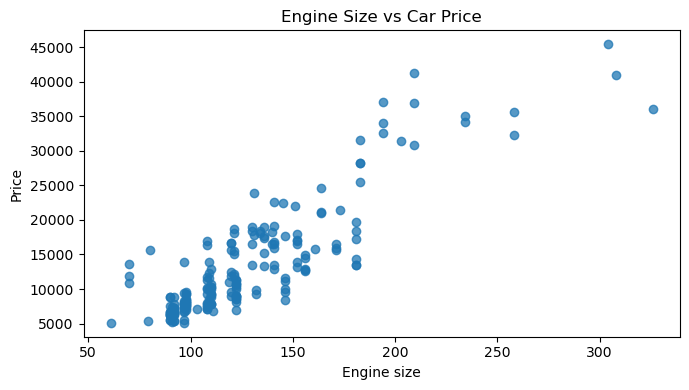

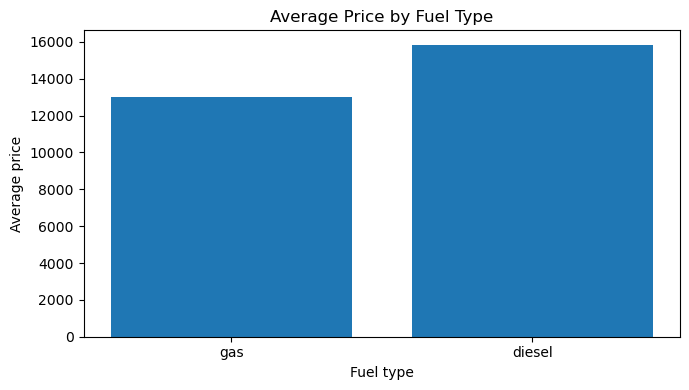

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("CarPrice_Assignment.csv")
print("Dataset shape:", data.shape)
print(data.head())
print(data.info())

print("Missing values per column:")
print(data.isnull().sum())
print("Duplicate rows:", data.duplicated().sum())

data = data.drop_duplicates().copy()
data["brand"] = data["CarName"].astype(str).str.split().str[0].str.lower()
data = data.drop(columns=["car_ID", "CarName"])

data = data.dropna(subset=["price"]).copy()
print("Shape after basic cleaning:", data.shape)
print("Target summary:")
print(data["price"].describe())

plt.figure(figsize=(7, 4))
plt.hist(data["price"], bins=20, edgecolor="black")
plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Number of cars")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.scatter(data["enginesize"], data["price"], alpha=0.75)
plt.title("Engine Size vs Car Price")
plt.xlabel("Engine size")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

average_fuel_price = data.groupby("fueltype")["price"].mean().sort_values()
plt.figure(figsize=(7, 4))
plt.bar(average_fuel_price.index, average_fuel_price.values)
plt.title("Average Price by Fuel Type")
plt.xlabel("Fuel type")
plt.ylabel("Average price")
plt.tight_layout()
plt.show()



In [35]:
X = data.drop(columns=["price"])
y = data["price"].to_numpy(dtype=float)

rng = np.random.default_rng(42)
indices = rng.permutation(len(data))
train_size = int(0.80 * len(data))
train_indices = indices[:train_size]
test_indices = indices[train_size:]

X_train_raw = X.iloc[train_indices].copy()
X_test_raw = X.iloc[test_indices].copy()
y_train = y[train_indices]
y_test = y[test_indices]

X_train_encoded = pd.get_dummies(X_train_raw, drop_first=False).astype(float)
X_test_encoded = pd.get_dummies(X_test_raw, drop_first=False).reindex(
    columns=X_train_encoded.columns, fill_value=0
).astype(float)

print("Training rows:", len(X_train_encoded))
print("Testing rows:", len(X_test_encoded))
print("Number of model features after encoding:", X_train_encoded.shape[1])

feature_mean = X_train_encoded.mean(axis=0).to_numpy()
feature_std = X_train_encoded.std(axis=0, ddof=0).to_numpy().copy()


feature_std[feature_std == 0] = 1.0
X_train_scaled = (X_train_encoded.to_numpy() - feature_mean) / feature_std
X_test_scaled = (X_test_encoded.to_numpy() - feature_mean) / feature_std

print("Training data scaled successfully.")
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)


learning_rate = 0.03
epochs = 3000
X_train_model = np.asarray(X_train_scaled, dtype=float)
y_train_model = np.asarray(y_train_scaled, dtype=float).reshape(-1)

weights = np.zeros(X_train_model.shape[1])
bias = 0.0
loss_history = []

m = len(y_train_model)

for epoch in range(epochs):
    # Predictions using current weights and bias
    predictions = np.dot(X_train_model, weights) + bias
    errors = predictions - y_train_model
#gradient
    dw = (2 / m) * np.dot(X_train_model.T, errors)
    db = (2 / m) * np.sum(errors)
# Updated
    weights = weights - learning_rate * dw
    bias = bias - learning_rate * db
    predictions = np.dot(X_train_model, weights) + bias
    loss = np.mean((predictions - y_train_model) ** 2)
    loss_history.append(loss)

print("Training completed!")
print("Number of loss values:", len(loss_history))
print("Final training loss:", loss_history[-1])


Training rows: 164
Testing rows: 41
Number of model features after encoding: 77
Training data scaled successfully.
Training shape: (164, 77)
Testing shape: (41, 77)
Training completed!
Number of loss values: 3000
Final training loss: 0.024121519704198277


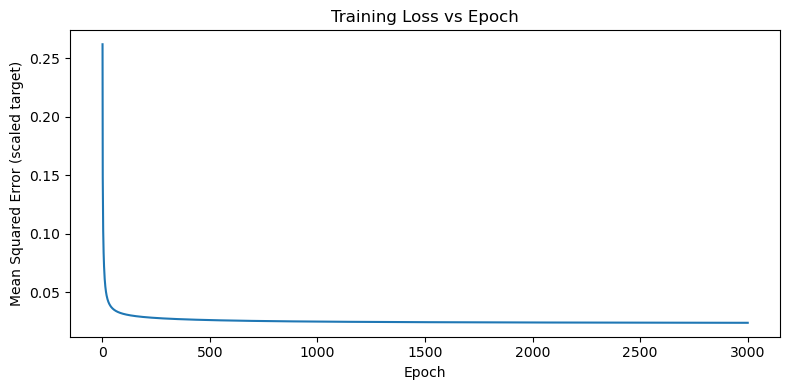

In [36]:

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(loss_history) + 1), loss_history)
plt.title("Training Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (scaled target)")
plt.tight_layout()
plt.show()

In [37]:
test_predictions_scaled = X_test_model @ weights
y_pred = test_predictions_scaled * y_std + y_mean

mae = np.mean(np.abs(y_test - y_pred))
rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))
ss_res = np.sum((y_test - y_pred) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
r2 = 1 - (ss_res / ss_tot) if ss_tot != 0 else float("nan")

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R-squared: {r2:.4f}")


MAE:  1998.81
RMSE: 2836.29
R-squared: 0.8857


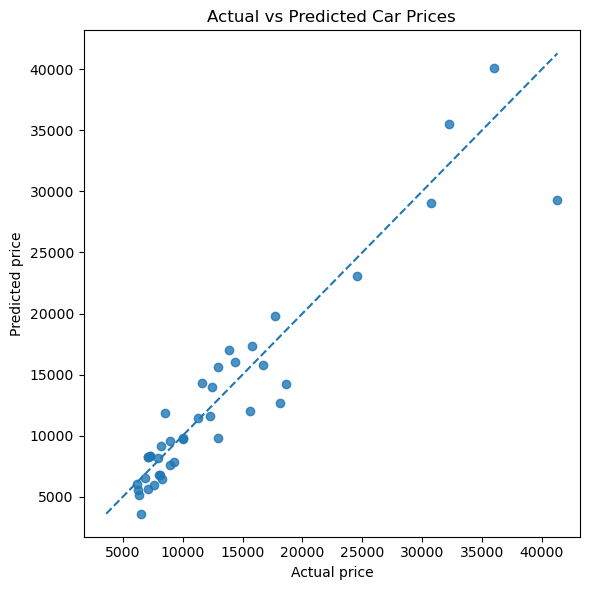

 Actual price  Predicted price  Absolute error
       9298.0          7799.15         1498.85
       7957.0          8129.72          172.72
       8238.0          6448.08         1789.92
       8948.0          9585.07          637.07
      30760.0         29034.93         1725.07
       8495.0         11824.44         3329.44
      12440.0         13989.59         1549.59
      18620.0         14211.13         4408.87
       6855.0          6538.10          316.90
      41315.0         29333.46        11981.54


In [38]:
#actual vs prediction 
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.8)
low = min(np.min(y_test), np.min(y_pred))
high = max(np.max(y_test), np.max(y_pred))
plt.plot([low, high], [low, high], linestyle="--")
plt.title("Actual vs Predicted Car Prices")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.tight_layout()
plt.show()

results = pd.DataFrame({
    "Actual price": y_test,
    "Predicted price": y_pred,
    "Absolute error": np.abs(y_test - y_pred)
})
print(results.head(10).round(2).to_string(index=False))
